# 非线性模型：梯度提升树

**研究问题：** 逻辑回归是线性的参照。换一个能拟合输入交互的模型后，筛选过的近期指标和交锋指标，哪一块对赛果更有帮助？

使用 `HistGradientBoostingClassifier`。输入组与 baseline 相同：NL0 只有 B，NL1 加近期，NL2 加交锋，NL3 两者都加。树的棵数只在 2020 年及以前的数据上用早停决定，再在截至 2022 年的数据上按这个棵数重训。测试期不参与拟合。

**输入：** `candidate_features.csv` 和 `selected_features.csv`。**输出：** 测试期三项概率和评分，写入 `data/results/nonlinear/`，并更新总报告。

## 1. 读取筛选后的指标

F、H 用预处理打印并保存的筛选结果。B 仍是 Elo 差、交锋次数和缺失标记，联赛做独热编码。

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd()
if not (ROOT / "data/processed/candidate_features.csv").exists():
    ROOT = ROOT.parent
RETRAIN = False
SEED, EPS = (20261028, 1e-15)
OUT = ROOT / "data/results/nonlinear"
(OUT / "models").mkdir(parents=True, exist_ok=True)
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
features = pd.read_csv(ROOT / "data/processed/candidate_features.csv", parse_dates=["MatchDate"])
features = features.sort_values(["MatchDate", "SourceRow"]).reset_index(drop=True)
selected = pd.read_csv(ROOT / "data/processed/selected_features.csv")
B = ["elo_diff", "h2h_count", "h2h_missing"]
F = selected.loc[selected.group.eq("recent_form"), "feature"].tolist()
H = selected.loc[selected.group.eq("head_to_head"), "feature"].tolist()
train = features.loc[features.split.eq("train")].reset_index(drop=True)
validation = features.loc[features.split.eq("validation")].reset_index(drop=True)
test = features.loc[features.split.eq("test")].reset_index(drop=True)
final_train = pd.concat([train, validation], ignore_index=True)
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(train[["Division"]])
print("Train / validation / test:", len(train), len(validation), len(test))
print("Recent form:", F)
print("Head-to-head:", H)

Train / validation / test: 106288 12598 11772
Recent form: ['recent_ppg_diff', 'recent_gd_diff', 'recent_win_rate_diff', 'recent_goals_for_diff', 'recent_goals_against_diff']
Head-to-head: ['h2h_ppg_diff', 'h2h_gd', 'h2h_win_rate', 'h2h_goals_for', 'h2h_goals_against']


## 2. 训练四个输入组

学习率 0.08，每个叶节点上限 31，L2 为 1。早停看训练期内随机抽出的 10%，最多 200 棵树，连续 15 轮验证损失不降就停止。最终模型不再早停，棵数固定为这一结果。

In [2]:
def matrix(frame, columns):
    numeric = frame[columns].to_numpy(float)
    division = encoder.transform(frame[["Division"]])
    return np.hstack([numeric, division])


def make_model(max_iter, early_stopping):
    return HistGradientBoostingClassifier(
        learning_rate=0.08,
        max_iter=max_iter,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        early_stopping=early_stopping,
        validation_fraction=0.1,
        n_iter_no_change=15,
        random_state=SEED,
    )


def normalize_probabilities(p):
    p = np.asarray(p, dtype=float)
    p = np.clip(p, EPS, 1)
    return p / p.sum(axis=1, keepdims=True)


def match_losses(frame, probabilities):
    p = normalize_probabilities(probabilities)
    y = frame.y.to_numpy(int)
    one_hot = np.eye(3)[y]
    target_q = frame[["q_H", "q_D", "q_A"]].to_numpy(float)
    return {
        "log_loss": -np.log(p[np.arange(len(frame)), y]),
        "brier": np.square(p - one_hot).sum(axis=1),
        "accuracy": (p.argmax(axis=1) == y).astype(float),
        "kl_to_odds": np.sum(target_q * (np.log(np.clip(target_q, EPS, 1)) - np.log(p)), axis=1),
    }


groups = {"NL0": B, "NL1": B + F, "NL2": B + H, "NL3": B + F + H}
saved_paths = [OUT / "models" / (name + ".joblib") for name in groups]
reuse = (not RETRAIN) and all(path.exists() for path in saved_paths)
if reuse:
    saved_inputs = joblib.load(saved_paths[1])["columns"]
    reuse = saved_inputs == groups["NL1"]
models = {}
if reuse:
    print("Using saved gradient boosting models; no training.")
    for name in groups:
        models[name] = joblib.load(OUT / "models" / (name + ".joblib"))["model"]
else:
    print("Training gradient boosting models.")
    for name, columns in groups.items():
        probe = make_model(200, True)
        probe.fit(matrix(train, columns), train.y.to_numpy(int))
        iterations = max(int(probe.n_iter_), 1)
        model = make_model(iterations, False)
        model.fit(matrix(final_train, columns), final_train.y.to_numpy(int))
        assert list(model.classes_) == [0, 1, 2]
        models[name] = model
        joblib.dump({"model": model, "columns": columns, "iterations": iterations}, OUT / "models" / (name + ".joblib"))
        print(name, "trees:", iterations)

predictions = {
    name: normalize_probabilities(model.predict_proba(matrix(test, groups[name])))
    for name, model in models.items()
}
predictions["Market"] = test[["q_H", "q_D", "q_A"]].to_numpy(float)
loss_arrays = {name: match_losses(test, probabilities) for name, probabilities in predictions.items()}
scores = pd.DataFrame(
    [
        {"model": name, "matches": len(test), **{metric: float(values.mean()) for metric, values in losses.items()}}
        for name, losses in loss_arrays.items()
    ]
)
scores.to_csv(OUT / "test_scores.csv", index=False)
print("Test scores")
display(scores.round(6))

Using saved gradient boosting models; no training.


Test scores


,model,matches,log_loss,brier,accuracy,kl_to_odds
0,NL0,11772,1.004729,0.600546,0.500510,0.016105
1,NL1,11772,1.002695,0.599367,0.500849,0.014711
2,NL2,11772,1.003673,0.599917,0.502973,0.015725
3,NL3,11772,1.002262,0.599082,0.503398,0.014708
4,Market,11772,0.987725,0.589294,0.519878,-0.000000


## 3. 近期和交锋的差别

配对差是同场 Log Loss 相减，负数表示左边更好。每个测试年按 28 天分块，有放回抽样 1000 次。区间跨 0 时，不把这次差异当成稳定差别。

,left,right,metric,difference,ci_low,ci_high,ci_includes_zero
0,NL1,NL0,log_loss,-0.002034,-0.003264,-0.000606,False
1,NL2,NL0,log_loss,-0.001056,-0.002514,0.000303,True
2,NL1,NL2,log_loss,-0.000978,-0.002418,0.000470,True
3,NL3,NL1,log_loss,-0.000433,-0.001523,0.000639,True
4,NL3,NL2,log_loss,-0.001411,-0.002766,-0.000168,False


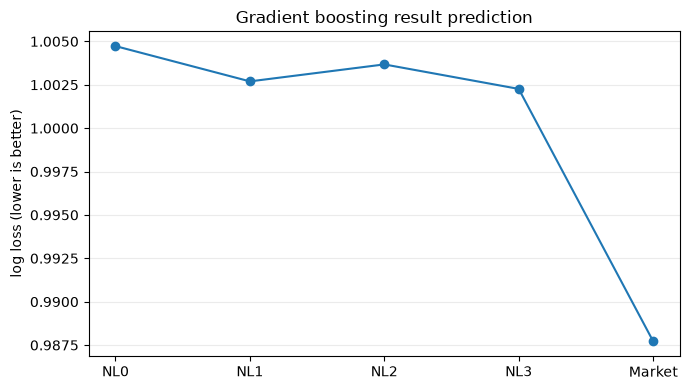

Updated reports/reports.md: nonlinear


In [3]:
rng = np.random.default_rng(SEED)
block_weights = []
blocks = []
for year in sorted(test.year.unique()):
    ids = np.flatnonzero(test.year.eq(year).to_numpy())
    day_index = (test.loc[ids, "MatchDate"] - pd.Timestamp(f"{int(year)}-01-01")).dt.days.to_numpy()
    group_id = day_index // 28
    year_blocks = [ids[group_id == group] for group in np.unique(group_id)]
    n_blocks = len(year_blocks)
    draws = rng.integers(0, n_blocks, size=(1000, n_blocks))
    counts = np.zeros((1000, n_blocks), dtype=int)
    for j in range(n_blocks):
        counts[:, j] = (draws == j).sum(axis=1)
    block_weights.append(counts)
    blocks.extend(year_blocks)
weights = np.concatenate(block_weights, axis=1)
block_sizes = np.array([len(ids) for ids in blocks])
bootstrap_denominator = weights @ block_sizes


def paired_difference(left, right):
    difference = loss_arrays[left]["log_loss"] - loss_arrays[right]["log_loss"]
    sums = np.array([difference[ids].sum() for ids in blocks])
    bootstrap = weights @ sums / bootstrap_denominator
    low, high = np.quantile(bootstrap, [0.025, 0.975])
    return {
        "left": left,
        "right": right,
        "metric": "log_loss",
        "difference": float(difference.mean()),
        "ci_low": float(low),
        "ci_high": float(high),
        "ci_includes_zero": bool(low <= 0 <= high),
    }


paired = pd.DataFrame(
    [paired_difference(left, right) for left, right in [("NL1", "NL0"), ("NL2", "NL0"), ("NL1", "NL2"), ("NL3", "NL1"), ("NL3", "NL2")]]
)
paired.to_csv(OUT / "paired_comparisons.csv", index=False)
display(paired.round(6))


def md_table(frame):
    rows = [
        "| " + " | ".join(map(str, frame.columns)) + " |",
        "| " + " | ".join(["---"] * len(frame.columns)) + " |",
    ]
    for values in frame.itertuples(index=False, name=None):
        rows.append("| " + " | ".join(f"{v:.6f}" if isinstance(v, (float, np.floating)) else str(v) for v in values) + " |")
    return "\n".join(rows)


def update_report(section, text):
    path = ROOT / "reports/reports.md"
    body = path.read_text(encoding="utf-8") if path.exists() else "# 足球比赛分析\n\n"
    start, end = (f"<!-- {section}:start -->", f"<!-- {section}:end -->")
    block = start + "\n" + text.strip() + "\n" + end
    if start in body:
        before, remainder = body.split(start, 1)
        _, after = remainder.split(end, 1)
        body = before + block + after
    else:
        body = body.rstrip() + "\n\n" + block + "\n"
    path.write_text(body, encoding="utf-8")
    print("Updated reports/reports.md:", section)


indexed = scores.set_index("model")
order = ["NL0", "NL1", "NL2", "NL3", "Market"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(order, indexed.loc[order, "log_loss"], "o-")
ax.set(title="Gradient boosting result prediction", ylabel="log loss (lower is better)")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES / "nonlinear.png", dpi=160)
plt.show()
nl1_vs_nl2 = paired.loc[paired.left.eq("NL1") & paired.right.eq("NL2")].iloc[0]
if nl1_vs_nl2.ci_includes_zero:
    comparison = "NL1 减 NL2 的 Log Loss 区间包含 0。这次梯度提升没有显示筛选后的近期状态和历史交锋之间有稳定差距。"
elif nl1_vs_nl2.difference < 0:
    comparison = "NL1 的 Log Loss 低于 NL2，且区间不包含 0。在这个树模型里，筛选后的近期指标比交锋指标更有帮助。"
else:
    comparison = "NL2 的 Log Loss 低于 NL1，且区间不包含 0。在这个树模型里，筛选后的交锋指标比近期指标更有帮助。"
text = "### 梯度提升\n\n"
text += "测试集与逻辑回归相同。NL0 = B，NL1 = B + 近期，NL2 = B + 交锋，NL3 = B + 两者。\n\n"
text += md_table(indexed.loc[order, ["log_loss", "accuracy"]].reset_index()) + "\n\n"
text += md_table(paired[["left", "right", "difference", "ci_low", "ci_high"]]) + "\n\n"
text += comparison + "\n\n"
text += "![梯度提升比较](figures/nonlinear.png)"
update_report("nonlinear", text)
